# Is Bitcoin a Safe Haven? Evidence from the 2026 Strait of Hormuz Crisis

**Author:** Xiang Zheng, University of Toronto

**Question.** When a war or crisis breaks out, do Bitcoin and gold protect investors by holding their value when stocks fall, or do they fall along with stocks?

**How I answer it.**
1. Look at how prices moved around six key moments in the 2026 Strait of Hormuz crisis.
2. Compare how closely Bitcoin and gold followed the stock market, oil, the US dollar and interest rates before and during the conflict, using several different "before" periods.
3. Compare 2026 with six earlier market shocks since 2019.
4. Apply a standard test from academic research (Baur and Lucey, 2010) that looks at the worst days for the stock market in 2019–2025.

**Data.** Daily prices from the Massive API (formerly Polygon.io) and, for Bitcoin before October 2024, Yahoo Finance. The raw prices are not included in this repository because of the data provider's license terms; to reproduce the results, run this notebook with your own Massive API key.

The text explains each step in plain language. Exact model definitions and the key numbers are collected in the **Technical notes** at the end.

## 1. Setup and data download

The API key is typed in when the notebook runs and is never saved in the file.

| Name | Ticker | What it represents |
|---|---|---|
| bitcoin | X:BTCUSD | Bitcoin (trades every day, around the clock) |
| sp500 | SPY | A fund that tracks the S&P 500, the 500 largest US companies |
| gold | GLD | A fund that tracks the price of gold |
| brent | BNO | A fund that tracks Brent crude oil |
| gold_spot | C:XAUUSD | The gold price on the currency market (opens Sunday evening) |
| dollar | UUP | A fund that rises when the US dollar strengthens |
| tips | TIP | A fund of inflation-protected US government bonds (falls when inflation-adjusted interest rates rise) |

In [1]:
from getpass import getpass
from massive import RESTClient
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
import yfinance as yf

client = RESTClient(api_key=getpass("Massive API key: "))

def get_daily(ticker, start="2025-06-01", end="2026-10-09"):
    # Download daily closing prices for one ticker; returns a series indexed by date
    bars = client.list_aggs(ticker=ticker, multiplier=1, timespan="day",
                            from_=start, to=end, adjusted=True, limit=50000)
    df = pd.DataFrame([{"date": pd.to_datetime(b.timestamp, unit="ms", utc=True).date(),
                        "close": b.close} for b in bars])
    s = df.set_index("date")["close"]
    s.index = pd.to_datetime(s.index)
    return s

Massive API key:  ········


In [2]:
tickers = {
    "X:BTCUSD": "bitcoin",
    "SPY": "sp500",
    "GLD": "gold",
    "BNO": "brent",
    "C:XAUUSD": "gold_spot",
    "UUP": "dollar",
    "TIP": "tips",
}

prices = pd.DataFrame({name: get_daily(t) for t, name in tickers.items()}).sort_index()
prices.to_csv("prices.csv")   # kept locally only (excluded by .gitignore)
print(prices.shape[0], "days,", prices.shape[1], "assets")

496 days, 7 assets


## 2. Lining up trading days and calculating daily changes

Bitcoin trades every day, the gold currency market trades Sunday to Friday, and the funds trade only on US market days, which is why some values are missing below. To compare like with like, I keep only US trading days, so Bitcoin's Monday change covers the whole weekend. One timing difference remains: Bitcoin's daily price is recorded at 8 p.m. New York time, four hours after the US stock market closes. Section 9 checks that this does not change the results.

In [3]:
print("Missing values by column:")
print(prices.isna().sum())

trading = prices.dropna(subset=["sp500"])
returns = np.log(trading / trading.shift(1)).iloc[1:]
returns.head()

Missing values by column:
bitcoin        0
sp500        154
gold         154
brent        154
gold_spot     71
dollar       154
tips         154
dtype: int64


,bitcoin,sp500,gold,brent,gold_spot,dollar,tips
date,,,,,,,
2025-06-03,-0.004326,0.005686,-0.008895,0.007140,-0.008167,0.006581,-0.000921
2025-06-04,-0.006607,-0.000268,0.006421,-0.010730,0.005305,-0.004383,0.003862
2025-06-05,-0.030859,-0.004844,-0.005063,0.006452,-0.004787,-0.000732,-0.002941
2025-06-06,0.027460,0.010217,-0.013507,0.018758,-0.015584,0.005115,-0.005353
2025-06-09,0.055004,0.000901,0.004707,0.007684,0.005175,-0.002554,0.001387


## 3. Events and price paths

Six key moments in the 2026 crisis. Dates come from news timelines, with announcement times where the sources report them. They should ideally be confirmed against original news reports, and I did not check whether other major economic news came out on the same days. The chart then shows how prices moved through 2026.

| Event | Date and time (ET) | First US trading day used | Source |
|---|---|---|---|
| US and Israeli strikes on Iran; Iran declares the strait closed | Sat Feb 28, 2026 (time not reported) | Mon Mar 2 | [Wikipedia: 2026 Strait of Hormuz campaign](https://en.wikipedia.org/wiki/2026_Strait_of_Hormuz_campaign) |
| Two-week ceasefire announced (takes effect April 8) | Tue Apr 7, evening, after the US close | Wed Apr 8 | [Wikipedia: 2026 Iran war ceasefire](https://en.wikipedia.org/wiki/2026_Iran_war_ceasefire) |
| Islamabad talks fail; US announces a naval blockade (effective Apr 13, 10:00 ET) | Sun Apr 12 | Mon Apr 13 | [Wikipedia: 2026 Iran war ceasefire](https://en.wikipedia.org/wiki/2026_Iran_war_ceasefire) |
| Islamabad Memorandum signed; strait reopens June 18 | Wed Jun 17 (signed at an evening dinner in France, during US trading hours) | Wed Jun 17 | [Wikipedia: 2026 Strait of Hormuz campaign](https://en.wikipedia.org/wiki/2026_Strait_of_Hormuz_campaign) |
| Ceasefire collapses; strait declared closed again on July 11 | Wed Jul 8 (time not reported) | Wed Jul 8 | [hormuz.now timeline](https://hormuz.now/timeline); [Crypto Briefing](https://cryptobriefing.com/iran-strait-hormuz-closure-bitcoin-market-impact/) |
| US forces destroy Iranian tankers after Iran's Revolutionary Guard fires on a US warship | Tue Sep 8 (time not reported) | Tue Sep 8 | [hormuz.now timeline](https://hormuz.now/timeline) |

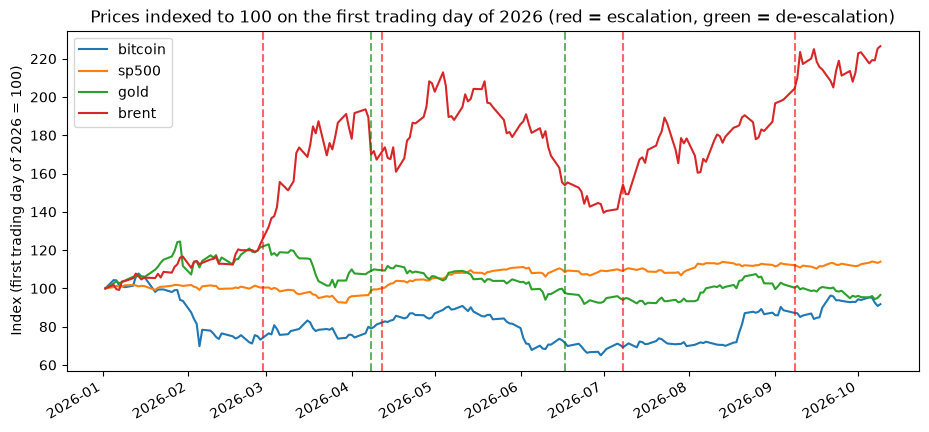

In [4]:
events = pd.DataFrame({
    "date": pd.to_datetime(["2026-02-28", "2026-04-08", "2026-04-12",
                            "2026-06-17", "2026-07-08", "2026-09-08"]),
    "label": ["War begins", "Ceasefire", "Blockade",
              "MOU signed", "Ceasefire collapses", "Tanker strikes"],
    "type": ["escalation", "de-escalation", "escalation",
             "de-escalation", "escalation", "escalation"],
})

def add_event_lines(ax):
    for _, e in events.iterrows():
        color = "red" if e["type"] == "escalation" else "green"
        ax.axvline(e["date"], color=color, linestyle="--", alpha=0.6)

norm = trading.loc["2026-01-01":, ["bitcoin", "sp500", "gold", "brent"]]
norm = norm / norm.iloc[0] * 100

fig, ax = plt.subplots(figsize=(11, 5))
norm.plot(ax=ax)
add_event_lines(ax)
ax.set_title("Prices indexed to 100 on the first trading day of 2026 (red = escalation, green = de-escalation)")
ax.set_ylabel("Index (first trading day of 2026 = 100)")
ax.set_xlabel("")
plt.savefig("price_paths.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. How did prices react on key days?

For each event, I compare each asset's move over the first two US trading days with its normal behaviour in a "before" period, June 2025 to January 2026. This period ends before the war and before an unrelated Bitcoin crash in early February 2026. It is not completely calm, because it includes the 12-day Israel–Iran conflict of June 2025, so Section 8 also checks other "before" periods.

The table shows each move in percent, together with a score of how unusual it is: a score beyond about 2 in either direction means the move was bigger than normal day-to-day swings.

In [5]:
baseline = returns.loc["2025-06-01":"2026-01-30"]
mu = baseline.mean()
sigma = baseline.std()
abnormal = returns - mu

def car(event_date, start, end):
    pos = abnormal.index.searchsorted(event_date)   # first trading day on or after the event
    return abnormal.iloc[pos + start : pos + end + 1].sum()

assets = ["bitcoin", "sp500", "gold", "brent"]
rows = []
for _, e in events.iterrows():
    c = car(e["date"], 0, 1)
    t = c / (sigma * np.sqrt(2))
    row = {"event": e["label"], "type": e["type"]}
    for a in assets:
        row[a] = round(c[a] * 100, 2)
        row[a + "_t"] = round(t[a], 2)
    rows.append(row)

car_table = pd.DataFrame(rows)
car_table

,event,type,bitcoin,bitcoin_t,sp500,sp500_t,gold,gold_t,brent,brent_t
0,War begins,escalation,3.95,1.19,-1.01,-1.07,-3.71,-1.71,10.16,4.05
1,Ceasefire,de-escalation,0.12,0.04,2.90,3.06,0.98,0.45,-10.01,-3.99
2,Blockade,escalation,1.88,0.57,2.00,2.11,1.38,0.64,0.35,0.14
3,MOU signed,de-escalation,-3.99,-1.20,-0.67,-0.70,-3.11,-1.43,-0.22,-0.09
4,Ceasefire collapses,escalation,0.04,0.01,0.35,0.37,-0.24,-0.11,0.37,0.15
5,Tanker strikes,escalation,-1.49,-0.45,-1.20,-1.27,-1.27,-0.59,5.36,2.14


**Reading the table.** Oil reacts most clearly, which confirms that these dates were real shocks. None of Bitcoin's moves is bigger than its normal swings. Bitcoin swings so much from day to day (about 2.3%) that it would need to move about 6–7% in two days to stand out, so this does not prove that it did not react.

### Taking out the stock market's influence

The table above compares each asset with its own average. But if stocks fell sharply on an event day, Bitcoin might fall simply because it usually follows stocks. Here I first take out the part of each move that the stock market explains, based on how closely each asset followed stocks in the before period, and look at what is left over one, two and three trading days after each event.

To judge whether a move is unusual, I count how often a move at least that large happened in the before period. If that share is below 5%, the move is rare.

In [6]:
market_model = {a: smf.ols(f"{a} ~ sp500", data=baseline).fit() for a in ["bitcoin", "gold"]}
ar_mm = pd.DataFrame({a: returns[a] - (m.params["Intercept"] + m.params["sp500"] * returns["sp500"])
                      for a, m in market_model.items()})

def empirical_p(asset, car_value, k):
    base_cars = ar_mm.loc[baseline.index, asset].rolling(k).sum().dropna()
    return (base_cars.abs() >= abs(car_value)).mean()

rows = []
for _, e in events.iterrows():
    pos = ar_mm.index.searchsorted(e["date"])
    for k in [1, 2, 3]:
        row = {"event": e["label"], "days": k}
        for a in ["bitcoin", "gold"]:
            c = ar_mm[a].iloc[pos:pos + k].sum()
            row[a + "_%"] = round(100 * c, 2)
            row[a + "_emp_p"] = round(empirical_p(a, c, k), 3)
        rows.append(row)
mm_table = pd.DataFrame(rows)
mm_table

,event,days,bitcoin_%,bitcoin_emp_p,gold_%,gold_emp_p
0,War begins,1,4.60,0.036,1.07,0.293
1,War begins,2,5.84,0.036,-3.63,0.060
2,War begins,3,11.01,0.000,-3.11,0.170
3,Ceasefire,1,-5.53,0.012,0.23,0.814
4,Ceasefire,2,-5.30,0.054,0.75,0.608
5,Ceasefire,3,-3.21,0.291,0.37,0.855
6,Blockade,1,0.46,0.820,-0.69,0.485
7,Blockade,2,-1.85,0.458,1.22,0.422
8,Blockade,3,-2.12,0.442,-0.09,0.958
9,MOU signed,1,0.86,0.593,-2.41,0.042


**Reading the table.** Gold shows no consistent reaction: only one of its 18 results is rare, which is about what chance alone would produce with this many comparisons. Bitcoin looks more striking. After allowing for the stock market, it did about 4.6% better than expected on the first trading day after the war began (about 11% over three days) and about 5.5% worse than expected on the first trading day of the ceasefire.

Section 9 shows that these results depend on the before period. In that period Bitcoin followed stocks unusually closely, which exaggerates how far it "should" have moved, and neither move stands out against Bitcoin's swings over 2019–2025. So I treat this part as supporting evidence only.

## 5. Did Bitcoin start moving more with other assets?

I measure how closely Bitcoin's daily moves matched those of stocks, gold, oil and the other assets, before and during the war (the war period starts on March 2, 2026, the first US trading day after it began), and how this changed over time using rolling 30-day windows. I also test whether each change is bigger than chance would produce.

One caution from earlier research (Forbes and Rigobon, 2002): these measures tend to rise automatically when markets become more turbulent, so I treat them as supporting evidence only.

In [7]:
calm = returns.loc["2025-06-01":"2026-01-30"]
war = returns.loc["2026-03-02":]

corr_table = pd.DataFrame({
    "baseline (Jun 2025 - Jan 2026)": calm.corr()["bitcoin"],
    "war (Mar - Oct 2026)": war.corr()["bitcoin"],
}).round(2)
corr_table

,baseline (Jun 2025 - Jan 2026),war (Mar - Oct 2026)
bitcoin,1.00,1.00
sp500,0.53,0.41
gold,0.10,0.43
brent,0.03,-0.18
gold_spot,0.12,0.47
dollar,-0.04,-0.26
tips,0.13,0.14


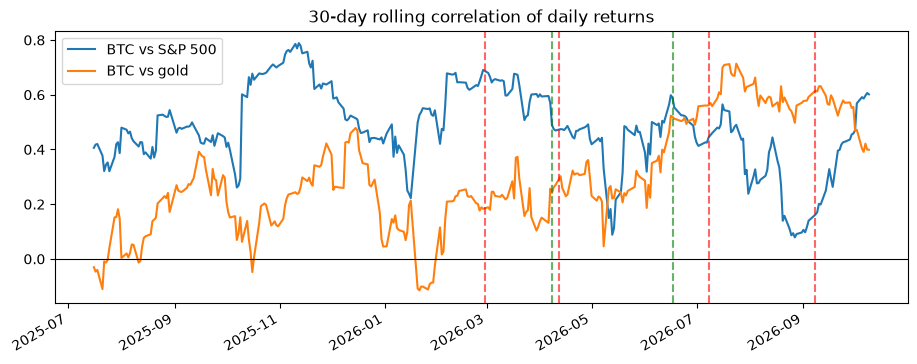

In [8]:
roll = pd.DataFrame({
    "BTC vs S&P 500": returns["bitcoin"].rolling(30).corr(returns["sp500"]),
    "BTC vs gold": returns["bitcoin"].rolling(30).corr(returns["gold"]),
})
fig, ax = plt.subplots(figsize=(11, 4))
roll.plot(ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
add_event_lines(ax)
ax.set_title("30-day rolling correlation of daily returns")
ax.set_xlabel("")
plt.show()

In [9]:
def fisher_test(r1, n1, r2, n2):
    # Test whether two correlations from independent samples differ
    z = (np.arctanh(r2) - np.arctanh(r1)) / np.sqrt(1 / (n1 - 3) + 1 / (n2 - 3))
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    return z, p

for asset in ["sp500", "gold", "brent"]:
    r1 = calm["bitcoin"].corr(calm[asset])
    r2 = war["bitcoin"].corr(war[asset])
    z, p = fisher_test(r1, len(calm), r2, len(war))
    print(f"{asset:6s} baseline {r1:.2f} -> war {r2:.2f}   z = {z:.2f}, p = {p:.3f}")

sp500  baseline 0.53 -> war 0.41   z = -1.43, p = 0.153
gold   baseline 0.10 -> war 0.43   z = 3.20, p = 0.001
brent  baseline 0.03 -> war -0.18   z = -1.91, p = 0.056


## 6. The dollar and interest rates

One possible reason Bitcoin and gold moved together: neither pays interest, so both may lose value when the dollar strengthens and inflation-adjusted interest rates rise. If that were the main story, both should tend to fall when the dollar fund rises, and to move in the same direction as the inflation-protected bond fund (whose price falls when those interest rates rise).

In [10]:
cols = ["sp500", "brent", "dollar", "tips"]
pd.DataFrame({
    "BTC baseline":  calm.corr().loc["bitcoin", cols],
    "BTC war":   war.corr().loc["bitcoin", cols],
    "Gold baseline": calm.corr().loc["gold", cols],
    "Gold war":  war.corr().loc["gold", cols],
}).round(2)

,BTC baseline,BTC war,Gold baseline,Gold war
sp500,0.53,0.41,0.03,0.51
brent,0.03,-0.18,0.03,-0.25
dollar,-0.04,-0.26,-0.35,-0.48
tips,0.13,0.14,0.10,0.32


## 7. Looking at all the influences together

The stock market, oil, the dollar and interest rates are linked to one another, so looking at one pair at a time can mislead. Here I measure the link between each of these four and Bitcoin, and each of them and gold, all at the same time, separately for the before period and the war.

In [11]:
def factor_regression(data, y):
    X = sm.add_constant(data[["sp500", "brent", "dollar", "tips"]])
    return sm.OLS(data[y], X, missing="drop").fit(cov_type="HAC", cov_kwds={"maxlags": 5})

for period_name, data in [("baseline", calm), ("war", war)]:
    for y in ["bitcoin", "gold"]:
        m = factor_regression(data, y)
        print(f"\n=== {y}, {period_name} ===  R-squared: {m.rsquared:.2f}")
        print(m.summary().tables[1])


=== bitcoin, baseline ===  R-squared: 0.30
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0033      0.001     -2.330      0.020      -0.006      -0.001
sp500          1.8622      0.178     10.459      0.000       1.513       2.211
brent          0.0981      0.080      1.233      0.218      -0.058       0.254
dollar         0.1047      0.200      0.523      0.601      -0.288       0.497
tips           0.9800      0.728      1.346      0.178      -0.447       2.407

=== gold, baseline ===  R-squared: 0.13
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0019      0.001      1.873      0.061   -9.07e-05       0.004
sp500          0.0194      0.173      0.112      0.911      -0.319       0.358
brent          0.0669      0.047      1.430   

## 8. Did the link to stocks change during the war?

I combine the before period and the war period and test directly whether Bitcoin and gold followed the stock market more or less closely during the war, while still allowing for oil, the dollar and interest rates.

In [12]:
pooled = pd.concat([calm.assign(war=0), war.assign(war=1)])

for y in ["gold", "bitcoin"]:
    m = smf.ols(f"{y} ~ sp500 + dollar + brent + tips + war + war:sp500 + war:dollar",
                data=pooled).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    print(f"\n=== {y} ===")
    print(m.summary().tables[1])


=== gold ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0020      0.001      1.877      0.061   -8.69e-05       0.004
sp500          0.0078      0.178      0.044      0.965      -0.342       0.358
dollar        -1.0754      0.327     -3.288      0.001      -1.716      -0.434
brent          0.0420      0.033      1.285      0.199      -0.022       0.106
tips           0.3015      0.312      0.966      0.334      -0.310       0.913
war           -0.0035      0.002     -2.032      0.042      -0.007      -0.000
war:sp500      0.7822      0.296      2.641      0.008       0.202       1.363
war:dollar    -0.3268      0.683     -0.478      0.632      -1.666       1.012

=== bitcoin ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0032

**Caveat.** These changes are measured against June 2025 to January 2026. That period includes the June 2025 Israel–Iran conflict, and Bitcoin followed stocks unusually closely in it. The next part tests other before periods.

### Does the choice of "before" period matter?

I repeat a simpler version of the test, using the stock market only, with three other before periods: the last 60, 120 and 180 trading days before the war. The "change in war" column shows how much more closely each asset followed stocks during the war than in that period.

In [13]:
pre_war = returns.loc[:"2026-02-27"]
baselines = {
    "Jun 2025 - Jan 2026 (main)": calm,
    "60 trading days before the war": pre_war.iloc[-60:],
    "120 trading days before the war": pre_war.iloc[-120:],
    "180 trading days before the war": pre_war.iloc[-180:],
}

rows = []
for name, base in baselines.items():
    pooled_b = pd.concat([base.assign(war=0), war.assign(war=1)])
    for asset in ["gold", "bitcoin"]:
        m = smf.ols(f"{asset} ~ sp500 + war + war:sp500", data=pooled_b) \
               .fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        lo, hi = m.conf_int().loc["war:sp500"]
        rows.append({"baseline": name, "asset": asset, "baseline_days": len(base),
                     "baseline_beta": m.params["sp500"],
                     "change_in_war": m.params["war:sp500"],
                     "ci_low": lo, "ci_high": hi, "p_value": m.pvalues["war:sp500"]})
baseline_check = pd.DataFrame(rows).round(3)
baseline_check

,baseline,asset,baseline_days,baseline_beta,change_in_war,ci_low,ci_high,p_value
0,Jun 2025 - Jan 2026 (main),gold,167,0.077,0.940,0.470,1.411,0.000
1,Jun 2025 - Jan 2026 (main),bitcoin,167,1.865,-0.727,-1.269,-0.185,0.009
2,60 trading days before the war,gold,60,0.417,0.600,-0.465,1.665,0.270
3,60 trading days before the war,bitcoin,60,3.167,-2.029,-3.864,-0.194,0.030
4,120 trading days before the war,gold,120,0.367,0.651,0.058,1.243,0.031
5,120 trading days before the war,bitcoin,120,2.565,-1.427,-2.416,-0.438,0.005
6,180 trading days before the war,gold,180,0.154,0.863,0.354,1.371,0.001
7,180 trading days before the war,bitcoin,180,2.242,-1.104,-1.939,-0.269,0.010


**Reading the table.** Gold followed stocks more closely during the war whichever before period is used, and the increase is clearly bigger than chance for three of the four. The exception is the last 60 days before the war: by then gold had already started to follow stocks somewhat, so the change began before the war.

Bitcoin followed stocks less closely during the war under every before period, but only because it had followed them unusually closely just before the war. During the war it moved roughly as much as stocks, close to its usual 2019–2025 behaviour, so this is a return to normal, not a sign that Bitcoin became a safe haven.

The main result for gold here (+0.94) is a little larger than in the previous section (+0.78) because this simpler version does not allow for oil, the dollar and interest rates.

### Does their shared link to stocks explain why Bitcoin and gold moved together?

If Bitcoin and gold moved together during the war only because both were following the stock market, the link between them should mostly disappear once each asset's stock-market-driven moves are taken out. I take those moves out and measure the link between what is left. This splits the link into parts; it does not prove what caused it.

In [14]:
def resid_on_stocks(data, y):
    return smf.ols(f"{y} ~ sp500", data=data).fit().resid

for period_name, data in [("baseline", calm), ("war", war)]:
    raw = data["bitcoin"].corr(data["gold"])
    partial = resid_on_stocks(data, "bitcoin").corr(resid_on_stocks(data, "gold"))
    print(f"{period_name:5s} Bitcoin-gold correlation: raw {raw:.2f}, after removing stock-market moves {partial:.2f}")

baseline Bitcoin-gold correlation: raw 0.10, after removing stock-market moves 0.10
war   Bitcoin-gold correlation: raw 0.43, after removing stock-market moves 0.29


## 9. Checking the data and building a longer history

My Massive data plan covers Bitcoin for only two years, so Bitcoin prices before October 2024 come from Yahoo Finance. Where both sources overlap, I check that they give the same daily moves. The long history from 2019 onward then uses Yahoo Finance for Bitcoin and Massive for everything else.

In [15]:
btc_yf = yf.download("BTC-USD", start="2019-01-01", end="2026-10-10",
                     auto_adjust=True)["Close"].squeeze()
btc_yf.index = pd.to_datetime(btc_yf.index).tz_localize(None)

both = pd.DataFrame({"massive": prices["bitcoin"], "yfinance": btc_yf}).dropna()
r = np.log(both / both.shift(1)).dropna()
print(len(r), "overlapping days")
r.corr()

[*********************100%***********************]  1 of 1 completed

495 overlapping days


,massive,yfinance
massive,1.000000,0.999532
yfinance,0.999532,1.000000


In [16]:
hist = pd.DataFrame({name: get_daily(t, start="2019-01-01")
                     for t, name in {"SPY": "sp500", "GLD": "gold",
                                     "BNO": "brent", "UUP": "dollar"}.items()})
hist["bitcoin"] = btc_yf
hist = hist.sort_index().dropna(subset=["sp500"])
hret = np.log(hist / hist.shift(1)).iloc[1:]
hret.tail()

,sp500,gold,brent,dollar,bitcoin
date,,,,,
2026-10-05,0.006721,-0.001553,-0.026497,0.003455,0.015144
2026-10-06,0.005483,0.007141,0.007781,-0.003109,-0.002673
2026-10-07,-0.002403,-0.016857,-0.000485,0.004833,-0.027030
2026-10-08,-0.004242,0.007263,0.027722,-0.002068,-0.019395
2026-10-09,0.005977,0.015619,0.005485,0.001379,0.010595


### Check: Bitcoin priced at the US market close

Bitcoin's daily price above is recorded at 8 p.m. New York time, four hours after the US stock market closes. Here I rebuild it from hourly prices using the price at 4 p.m., when US stocks close, and check whether the 2026 results change.

In [17]:
import time

def get_hourly(ticker, start, end, chunk_days=30, pause=13):
    # Download hourly bars one month at a time, pausing between requests to stay under the API rate limit
    pieces = []
    for s in pd.date_range(start, end, freq=f"{chunk_days}D"):
        e = min(s + pd.Timedelta(days=chunk_days - 1), pd.Timestamp(end))
        for attempt in range(5):
            try:
                bars = list(client.list_aggs(ticker=ticker, multiplier=1, timespan="hour",
                                             from_=s.strftime("%Y-%m-%d"), to=e.strftime("%Y-%m-%d"),
                                             adjusted=True, limit=50000))
                break
            except Exception:
                print(f"  rate limit hit, waiting 60 seconds (attempt {attempt + 1} of 5)")
                time.sleep(60)
        else:
            raise RuntimeError(f"could not download {s.date()} to {e.date()}")
        pieces += [{"t": pd.to_datetime(b.timestamp, unit="ms", utc=True), "close": b.close} for b in bars]
        print(f"{s.date()} to {e.date()}: {len(bars)} hourly bars")
        time.sleep(pause)
    df = pd.DataFrame(pieces).drop_duplicates("t").set_index("t").sort_index()
    return df["close"].tz_convert("America/New_York")

btc_hourly = get_hourly("X:BTCUSD", "2025-06-01", "2026-10-09")
# The hourly bar that starts at 15:00 ET closes at 16:00 ET
btc_4pm = btc_hourly[btc_hourly.index.hour == 15].copy()
btc_4pm.index = btc_4pm.index.tz_localize(None).normalize()

close_aligned = trading[["sp500", "gold"]].join(btc_4pm.rename("bitcoin_4pm"), how="left")
ret_4pm = np.log(close_aligned / close_aligned.shift(1)).iloc[1:]
ret_4pm["bitcoin"] = returns["bitcoin"]

rows = []
for period_name, data in [("baseline", ret_4pm.loc["2025-06-01":"2026-01-30"]), ("war", ret_4pm.loc["2026-03-02":])]:
    for col in ["bitcoin", "bitcoin_4pm"]:
        d = data[[col, "sp500", "gold"]].dropna()
        rows.append({"period": period_name, "bitcoin_price_time": "midnight UTC" if col == "bitcoin" else "4 p.m. ET",
                     "days": len(d),
                     "beta_to_sp500": d[col].cov(d["sp500"]) / d["sp500"].var(),
                     "corr_with_sp500": d[col].corr(d["sp500"]),
                     "corr_with_gold": d[col].corr(d["gold"])})
btc_time_check = pd.DataFrame(rows).round(3)
btc_time_check

2025-06-01 to 2025-06-30: 720 hourly bars
2025-07-01 to 2025-07-30: 720 hourly bars
2025-07-31 to 2025-08-29: 720 hourly bars
2025-08-30 to 2025-09-28: 720 hourly bars
2025-09-29 to 2025-10-28: 720 hourly bars
2025-10-29 to 2025-11-27: 720 hourly bars
2025-11-28 to 2025-12-27: 720 hourly bars
2025-12-28 to 2026-01-26: 720 hourly bars
2026-01-27 to 2026-02-25: 720 hourly bars
2026-02-26 to 2026-03-27: 720 hourly bars
2026-03-28 to 2026-04-26: 720 hourly bars
2026-04-27 to 2026-05-26: 720 hourly bars
2026-05-27 to 2026-06-25: 720 hourly bars
2026-06-26 to 2026-07-25: 720 hourly bars
2026-07-26 to 2026-08-24: 720 hourly bars
2026-08-25 to 2026-09-23: 720 hourly bars
2026-09-24 to 2026-10-09: 384 hourly bars


,period,bitcoin_price_time,days,beta_to_sp500,corr_with_sp500,corr_with_gold
0,baseline,midnight UTC,167,1.865,0.533,0.103
1,baseline,4 p.m. ET,167,1.715,0.465,0.057
2,war,midnight UTC,155,1.138,0.408,0.433
3,war,4 p.m. ET,155,1.375,0.476,0.451


**Reading the table.** Using the 4 p.m. price does not change the conclusions. During the war Bitcoin still moved slightly more than stocks (1.38 instead of 1.14 on a scale where 1 means moving as much as stocks), and its link with gold is almost the same (0.45 instead of 0.43), so the timing difference does not explain why Bitcoin and gold moved together.

### Check: taking out the stock market using its long-run influence

Section 4 took out the stock market's influence based on the before period, when Bitcoin moved almost twice as much as stocks. Over 2019–2025 it moved roughly as much as stocks. If the before period exaggerates the link, then on a day when stocks fall, Bitcoin will look as if it did better than expected. Here I repeat the calculation using the 2019–2025 link, judge each move against all moves of the same length in 2019–2025, and show the actual moves alongside.

In [18]:
long_run = hret.loc["2019-01-01":"2025-12-31", ["sp500", "gold", "bitcoin"]].dropna()
market_model_lr = {a: smf.ols(f"{a} ~ sp500", data=long_run).fit() for a in ["bitcoin", "gold"]}
ar_lr = pd.DataFrame({a: returns[a] - (m.params["Intercept"] + m.params["sp500"] * returns["sp500"])
                      for a, m in market_model_lr.items()})
ar_lr_hist = pd.DataFrame({a: long_run[a] - (m.params["Intercept"] + m.params["sp500"] * long_run["sp500"])
                           for a, m in market_model_lr.items()})
print({a: round(m.params["sp500"], 2) for a, m in market_model_lr.items()}, "= 2019-2025 betas")
print({a: round(m.params["sp500"], 2) for a, m in market_model.items()}, "= baseline betas")

rows = []
for _, e in events.iterrows():
    pos = returns.index.searchsorted(e["date"])
    for k in [1, 2, 3]:
        win = slice(pos, pos + k)
        row = {"event": e["label"], "days": k,
               "sp500_raw_%": round(100 * returns["sp500"].iloc[win].sum(), 2)}
        for a in ["bitcoin", "gold"]:
            c_lr = ar_lr[a].iloc[win].sum()
            hist_cars = ar_lr_hist[a].rolling(k).sum().dropna()
            row[a + "_raw_%"] = round(100 * returns[a].iloc[win].sum(), 2)
            row[a + "_adj_baseline_%"] = round(100 * ar_mm[a].iloc[win].sum(), 2)
            row[a + "_adj_longrun_%"] = round(100 * c_lr, 2)
            row[a + "_longrun_emp_p"] = round((hist_cars.abs() >= abs(c_lr)).mean(), 3)
        rows.append(row)
event_check = pd.DataFrame(rows)
pd.set_option("display.max_columns", None)
event_check

{'bitcoin': np.float64(1.05), 'gold': np.float64(0.08)} = 2019-2025 betas
{'bitcoin': np.float64(1.87), 'gold': np.float64(0.08)} = baseline betas


,event,days,sp500_raw_%,bitcoin_raw_%,bitcoin_adj_baseline_%,bitcoin_adj_longrun_%,bitcoin_longrun_emp_p,gold_raw_%,gold_adj_baseline_%,gold_adj_longrun_%,gold_longrun_emp_p
0,War begins,1,0.06,4.40,4.60,4.22,0.185,1.28,1.07,1.22,0.177
1,War begins,2,-0.83,3.68,5.84,4.32,0.297,-3.28,-3.63,-3.34,0.025
2,War begins,3,-0.13,9.84,11.01,9.63,0.110,-2.50,-3.11,-2.68,0.102
3,Ceasefire,1,2.52,-1.15,-5.53,-3.92,0.203,0.63,0.23,0.36,0.630
4,Ceasefire,2,3.09,-0.16,-5.30,-3.64,0.355,1.40,0.75,1.02,0.392
5,Ceasefire,3,3.02,1.50,-3.21,-2.03,0.653,1.22,0.37,0.79,0.590
6,Blockade,1,0.97,1.96,0.46,0.82,0.721,-0.41,-0.69,-0.55,0.488
7,Blockade,2,2.18,1.61,-1.85,-0.93,0.777,1.80,1.22,1.50,0.242
8,Blockade,3,2.97,2.49,-2.12,-0.99,0.826,0.76,-0.09,0.33,0.817
9,MOU signed,1,-1.26,-1.80,0.86,-0.59,0.787,-2.30,-2.41,-2.26,0.031


**Reading the table.** Measured this way, none of Bitcoin's moves after the six events stands out from its usual swings over 2019–2025. The largest came at the start of the war: Bitcoin rose about 4% on the first trading day and about 10% over three days while US stocks barely moved. That is large compared with the calmer months of late 2025 but not compared with 2019–2025, so it is a possible reaction, not a confirmed one.

Gold fell about 3% in the two days after the war began, the opposite of what a safe haven would do, but with 36 comparisons in the table one result like this is not strong evidence.

## 10. Was 2026 unusual? Comparison with earlier market shocks

I measure how closely gold and Bitcoin followed the stock market during seven market shocks since 2019, and over all days in 2019–2025 for comparison. On this scale, 0 means no link to stocks and 1 means moving as much as stocks, in the same direction. The table also shows how much each asset gained or lost over each window, in percent. The time windows and the grouping of shocks by type are my own choices.

In [19]:
episodes = {
    "COVID crash (2020)":             ("2020-02-24", "2020-04-30", "financial stress"),
    "Russia invades Ukraine (2022)":  ("2022-02-24", "2022-06-30", "oil/inflation"),
    "SVB collapse (2023)":            ("2023-03-08", "2023-04-28", "financial stress"),
    "Yen carry unwind (2024)":        ("2024-07-15", "2024-09-13", "financial stress"),
    "Liberation Day tariffs (2025)":  ("2025-04-03", "2025-05-30", "financial stress"),
    "Israel strikes Iran (2025)":     ("2025-06-13", "2025-07-31", "oil/inflation"),
    "Hormuz war (2026)":              ("2026-03-02", "2026-10-09", "oil/inflation"),
    "All days 2019-2025 (benchmark)": ("2019-01-01", "2025-12-31", "benchmark"),
}

def beta(df, asset):
    return df[asset].cov(df["sp500"]) / df["sp500"].var()

rows = []
for name, (start, end, kind) in episodes.items():
    d = hret.loc[start:end]
    rows.append({
        "episode": name, "type": kind, "days": len(d),
        "gold_beta": round(beta(d, "gold"), 2),
        "btc_beta": round(beta(d, "bitcoin"), 2),
        "sp500_%": round((np.exp(d["sp500"].sum()) - 1) * 100, 1),
        "gold_%": round((np.exp(d["gold"].sum()) - 1) * 100, 1),
        "btc_%": round((np.exp(d["bitcoin"].sum()) - 1) * 100, 1),
    })
history_table = pd.DataFrame(rows)
history_table

,episode,type,days,gold_beta,btc_beta,sp500_%,gold_%,btc_%
0,COVID crash (2020),financial stress,48,0.10,1.14,-12.9,2.7,-10.6
1,Russia invades Ukraine (2022),oil/inflation,88,-0.06,1.70,-10.6,-5.5,-47.0
2,SVB collapse (2023),financial stress,37,-0.55,0.54,4.4,9.6,32.0
3,Yen carry unwind (2024),financial stress,44,0.41,2.08,0.4,7.0,4.6
4,Liberation Day tariffs (2025),financial stress,40,0.00,0.50,4.4,5.4,26.1
5,Israel strikes Iran (2025),oil/inflation,33,-0.59,1.07,4.7,-3.0,9.3
6,Hormuz war (2026),oil/inflation,155,1.02,1.14,13.5,-20.5,25.3
7,All days 2019-2025 (benchmark),benchmark,1759,0.08,1.05,172.6,226.6,2119.1


In [20]:
rows = []
for name, (start, end, kind) in episodes.items():
    d = hret.loc[start:end]
    for asset in ["gold", "bitcoin"]:
        m = smf.ols(f"{asset} ~ sp500", data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        lo, hi = m.conf_int().loc["sp500"]
        rows.append({"episode": name, "asset": asset,
                     "beta": round(m.params["sp500"], 2),
                     "ci_low": round(lo, 2), "ci_high": round(hi, 2),
                     "p_value": round(m.pvalues["sp500"], 3)})
beta_ci = pd.DataFrame(rows)
beta_ci

,episode,asset,beta,ci_low,ci_high,p_value
0,COVID crash (2020),gold,0.10,-0.00,0.19,0.053
1,COVID crash (2020),bitcoin,1.14,0.39,1.90,0.003
2,Russia invades Ukraine (2022),gold,-0.06,-0.22,0.09,0.435
3,Russia invades Ukraine (2022),bitcoin,1.70,1.01,2.40,0.000
4,SVB collapse (2023),gold,-0.55,-0.89,-0.20,0.002
5,SVB collapse (2023),bitcoin,0.54,-0.42,1.50,0.273
6,Yen carry unwind (2024),gold,0.41,0.28,0.54,0.000
7,Yen carry unwind (2024),bitcoin,2.08,0.84,3.32,0.001
8,Liberation Day tariffs (2025),gold,0.00,-0.37,0.38,0.981
9,Liberation Day tariffs (2025),bitcoin,0.50,0.16,0.84,0.004


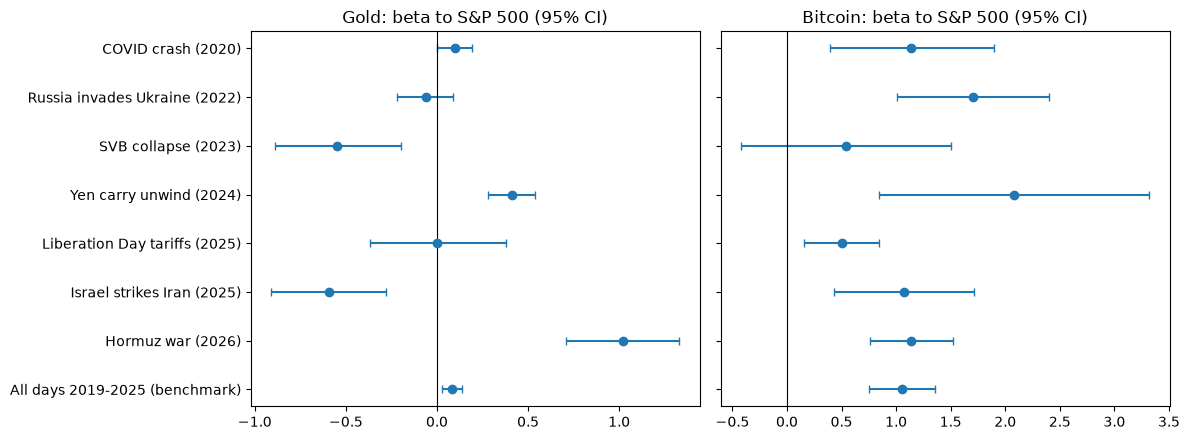

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, asset in zip(axes, ["gold", "bitcoin"]):
    d = beta_ci[beta_ci["asset"] == asset].reset_index(drop=True)
    y = range(len(d))
    ax.errorbar(d["beta"], y,
                xerr=[d["beta"] - d["ci_low"], d["ci_high"] - d["beta"]],
                fmt="o", capsize=3)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{asset.capitalize()}: beta to S&P 500 (95% CI)")
    ax.set_yticks(list(y))
    ax.set_yticklabels(d["episode"])
axes[0].invert_yaxis()
plt.tight_layout()
plt.savefig("beta_by_episode.png", dpi=150, bbox_inches="tight")
plt.show()

### Check: same-length windows

The windows above range from 33 to 155 trading days, so some mix early panic with later recovery more than others. Here every shock uses only its first 40 trading days.

In [22]:
rows = []
for name, (start, end, kind) in episodes.items():
    if kind == "benchmark":
        continue
    d = hret.loc[start:].iloc[:40]   # first 40 trading days from the start, regardless of the original window
    for asset in ["gold", "bitcoin"]:
        m = smf.ols(f"{asset} ~ sp500", data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        lo, hi = m.conf_int().loc["sp500"]
        rows.append({"episode": name, "asset": asset, "days": len(d),
                     "first_day": d.index[0].date(), "last_day": d.index[-1].date(),
                     "beta": round(m.params["sp500"], 2),
                     "ci_low": round(lo, 2), "ci_high": round(hi, 2)})
beta_40 = pd.DataFrame(rows)
beta_40

,episode,asset,days,first_day,last_day,beta,ci_low,ci_high
0,COVID crash (2020),gold,40,2020-02-24,2020-04-20,0.09,-0.01,0.19
1,COVID crash (2020),bitcoin,40,2020-02-24,2020-04-20,1.11,0.35,1.88
2,Russia invades Ukraine (2022),gold,40,2022-02-24,2022-04-21,-0.42,-0.68,-0.16
3,Russia invades Ukraine (2022),bitcoin,40,2022-02-24,2022-04-21,1.45,0.80,2.11
4,SVB collapse (2023),gold,40,2023-03-08,2023-05-03,-0.58,-0.88,-0.27
5,SVB collapse (2023),bitcoin,40,2023-03-08,2023-05-03,0.48,-0.40,1.36
6,Yen carry unwind (2024),gold,40,2024-07-15,2024-09-09,0.40,0.27,0.53
7,Yen carry unwind (2024),bitcoin,40,2024-07-15,2024-09-09,2.11,0.82,3.40
8,Liberation Day tariffs (2025),gold,40,2025-04-03,2025-05-30,0.00,-0.37,0.38
9,Liberation Day tariffs (2025),bitcoin,40,2025-04-03,2025-05-30,0.50,0.16,0.84


**Reading the table.** Over the first 40 trading days, gold followed stocks more closely in 2026 (0.93) than in any of the other six shocks. The only other shock in which gold clearly moved with stocks was the market sell-off of summer 2024 that started in Japan (0.40). Bitcoin's 2026 result (1.04) is in the middle of its usual range.

## 11. What happens on the worst days for stocks? (Baur and Lucey, 2010)

This test, widely used in research on safe havens, measures how closely an asset follows stocks on normal days and on the worst days for the stock market in 2019–2025, split into the worst 5%, worst 2.5% and worst 1% of days.

- An asset is a **hedge** if, on average, it does not move with stocks.
- It is a **safe haven** if it does not fall along with stocks on the worst days.

The exact model is given in the Technical notes at the end.

In [23]:
sample = hret.loc["2019-01-01":"2025-12-31", ["sp500", "gold", "bitcoin"]].dropna().copy()

q05, q025, q01 = sample["sp500"].quantile([0.05, 0.025, 0.01])
sample["sp500_q05"]  = sample["sp500"] * (sample["sp500"] <= q05)
sample["sp500_q025"] = sample["sp500"] * (sample["sp500"] <= q025)
sample["sp500_q01"]  = sample["sp500"] * (sample["sp500"] <= q01)

print(f"Thresholds: 5% = {q05:.2%}, 2.5% = {q025:.2%}, 1% = {q01:.2%}")
print("Number of stress days:",
      (sample["sp500"] <= q05).sum(), (sample["sp500"] <= q025).sum(), (sample["sp500"] <= q01).sum())

stress_tests = [("normal days",       "sp500"),
                ("worst 2.5-5% days", "sp500 + sp500_q05"),
                ("worst 1-2.5% days", "sp500 + sp500_q05 + sp500_q025"),
                ("worst 1% days",     "sp500 + sp500_q05 + sp500_q025 + sp500_q01")]

def baur_lucey(data, label):
    for asset in ["gold", "bitcoin"]:
        m = smf.ols(f"{asset} ~ sp500 + sp500_q05 + sp500_q025 + sp500_q01", data=data) \
               .fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        print(f"\n=== {asset} ({label}) ===")
        for name, expr in stress_tests:
            t = m.t_test(f"{expr} = 0")
            print(f"{name:17s} total beta = {float(np.squeeze(t.effect)):6.3f}, "
                  f"p = {float(np.squeeze(t.pvalue)):.3f}")

baur_lucey(sample, "2019-2025")

Thresholds: 5% = -1.78%, 2.5% = -2.55%, 1% = -3.49%
Number of stress days: 88 44 18

=== gold (2019-2025) ===
normal days       total beta =  0.078, p = 0.098
worst 2.5-5% days total beta =  0.069, p = 0.469
worst 1-2.5% days total beta = -0.045, p = 0.664
worst 1% days     total beta =  0.144, p = 0.003

=== bitcoin (2019-2025) ===
normal days       total beta =  0.836, p = 0.000
worst 2.5-5% days total beta =  1.001, p = 0.015
worst 1-2.5% days total beta =  1.229, p = 0.001
worst 1% days     total beta =  1.583, p = 0.000


### The most extreme days

The days in the worst 1% for the S&P 500 in 2019–2025, with each asset's move in percent.

In [24]:
extreme = sample[sample["sp500"] <= q01][["sp500", "gold", "bitcoin"]]
(extreme * 100).round(2)

,sp500,gold,bitcoin
date,,,
2020-02-27,-4.60,0.02,-0.41
2020-03-09,-8.13,0.16,-14.09
2020-03-11,-5.00,-0.36,0.02
2020-03-12,-10.06,-4.07,-46.47
2020-03-16,-11.59,-1.15,-10.39
2020-03-18,-5.20,-2.01,0.24
2020-03-20,-4.99,1.49,0.12
2020-04-01,-4.60,0.94,2.58
2020-06-11,-5.94,-0.72,-5.72


### Check: leaving out the COVID crash

With so few extreme days, a single day (for example, March 12, 2020) can drive the result. I repeat the test without February 20 to April 30, 2020.

In [25]:
covid = (sample.index >= "2020-02-20") & (sample.index <= "2020-04-30")
sample_nc = sample[~covid]
print("Stress days left:",
      (sample_nc["sp500"] <= q05).sum(), (sample_nc["sp500"] <= q025).sum(), (sample_nc["sp500"] <= q01).sum())

baur_lucey(sample_nc, "excluding COVID crash")

Stress days left: 72 29 10

=== gold (excluding COVID crash) ===
normal days       total beta =  0.066, p = 0.121
worst 2.5-5% days total beta =  0.066, p = 0.497
worst 1-2.5% days total beta =  0.055, p = 0.564
worst 1% days     total beta =  0.163, p = 0.039

=== bitcoin (excluding COVID crash) ===
normal days       total beta =  0.870, p = 0.000
worst 2.5-5% days total beta =  0.980, p = 0.020
worst 1-2.5% days total beta =  1.657, p = 0.000
worst 1% days     total beta =  1.411, p = 0.021


### What did gold and Bitcoin do on the worst days for stocks in 2026?

The test above covers 2019–2025. For 2026, I list the war-period days when the S&P 500 fell by more than 1.78%, a fall that ranked among the worst 5% of days in 2019–2025, and compare gold's and Bitcoin's average moves on those days with similar days in 2019–2025, in percent.

In [26]:
war_h = hret.loc["2026-03-02":"2026-10-09", ["sp500", "gold", "bitcoin"]].dropna()
stress_2026 = war_h[war_h["sp500"] <= q05]
print(len(stress_2026), f"days in the war period with the S&P 500 down more than {abs(q05):.2%}")
(stress_2026 * 100).round(2)

2 days in the war period with the S&P 500 down more than 1.78%


,sp500,gold,bitcoin
date,,,
2026-03-26,-1.80,-3.83,-3.60
2026-06-05,-2.61,-3.72,-4.62


In [27]:
stress_hist = sample.loc[sample["sp500"] <= q05, ["sp500", "gold", "bitcoin"]]
pd.DataFrame({
    "2019-2025 stress days: average return %": stress_hist.mean() * 100,
    "2019-2025: share of days the asset fell": (stress_hist < 0).mean(),
    "2026 stress days: average return %": stress_2026.mean() * 100,
    "2026: share of days the asset fell": (stress_2026 < 0).mean(),
}).round(2)

,2019-2025 stress days: average return %,2019-2025: share of days the asset fell,2026 stress days: average return %,2026: share of days the asset fell
sp500,-3.06,1.00,-2.21,1.0
gold,-0.10,0.62,-3.78,1.0
bitcoin,-3.61,0.76,-4.11,1.0


## 12. Summary of findings

### What I wanted to know

When a war or crisis hits, investors often move their money into "safe havens": assets that are expected to hold their value when the stock market falls. Gold is the classic example, and some people argue that Bitcoin is "digital gold". I used the 2026 Strait of Hormuz crisis, when fighting around one of the world's most important oil routes sent oil prices sharply higher, to test whether either of them behaved this way.

### In short

Bitcoin behaved like a risky investment rather than a safe haven, as it has since 2019. Gold, unusually, rose and fell with the stock market during the 2026 conflict, but there were too few sharp market falls to tell whether it still protects investors in a crash. These are patterns in prices; on their own they cannot show that the war caused them.

### What I found

**Gold followed the stock market far more than usual.** Before the conflict, gold's daily moves had almost nothing to do with stocks; during it, the two often rose and fell together. This shows up against three of the four "before" periods I compared with, and when every shock is compared over the same length of time, and no other market shock since 2019 comes close, including a similar Israel–Iran conflict in June 2025. Part of the change had already started a few months before the war.

**On the two sharp market falls during the conflict, gold fell too,** and by more than stocks. On similar days in 2019–2025 it was roughly flat on average.

**For Bitcoin, the main evidence is its long-run behaviour.** Since 2019 it has tended to move about as much as US stocks, and even more than stocks on their very worst days. In 2026 it behaved in its usual way, whether its price is taken at the US market close or later in the evening. Its reactions on individual conflict days were mixed: it rose noticeably after the war began, but not by more than it often moves over a few ordinary trading days.

**Bitcoin and gold moved more closely together during the conflict.** Their shared link to stocks explains part of this, but not all.

### What this means

Whether an asset behaves as a safe haven is not a fixed fact; it can change from one crisis to the next, so investors should not assume gold will always move against stocks. I could not establish why 2026 was different. One possibility, which I did not test, is that some investors sold gold to lock in profits after its sharp rise in 2025.

### How confident am I?

- The 2026 conflict produced only six clear events to study.
- Some results depend on which "before" period is used, so I report several.
- Event dates come from news timelines, and I did not check for other economic news released on the same days.
- I use funds that track stocks, gold and oil as stand-ins for the assets themselves.

## 13. Technical notes

**Definitions.**
- Daily returns are log returns. Cumulative returns over a window are converted to simple percentage changes as exp(sum of log returns) − 1.
- **Beta** to the S&P 500 is the slope from regressing an asset's daily return on the S&P 500's daily return (0 = no relation, 1 = moves one-for-one).
- All regression standard errors are Newey-West (HAC, 5 lags), following Baur and Lucey (2010).

**Event study (Section 4).** Abnormal return = actual return − before-period mean. CAR(0,+1) is the sum over the first US trading day on or after the event and the next day; t = CAR / (σ√2), with σ the before-period standard deviation. The market-model version uses abnormal return = r − (α + β·r_S&P), with α and β estimated in the before period (Section 4) or over 2019–2025 (Section 9); empirical p-values are the share of rolling same-length windows in the estimation sample with an |abnormal return| at least as large.

**Correlations (Section 5).** Changes are tested with a Fisher z-test. The partial correlation in Section 8 is the correlation of residuals after regressing each asset on the S&P 500 within each period.

**Factor and interaction regressions (Sections 7–8).**
- asset = a + b1·S&P 500 + b2·oil + b3·dollar + b4·TIP + error, estimated separately for each period.
- Pooled: asset ~ S&P 500 + dollar + oil + TIP + war + war×S&P 500 + war×dollar; the war×S&P 500 coefficient is the change in beta. The baseline-sensitivity check uses asset ~ S&P 500 + war + war×S&P 500.

**Baur and Lucey (2010) test (Section 11).** asset = a + b1·S&P + b2·S&P·D(5%) + b3·S&P·D(2.5%) + b4·S&P·D(1%), where D(q) = 1 on days when the S&P 500 return is in its worst q% of 2019–2025. Because the groups are nested, the total beta is b1 on normal days, b1 + b2 on the worst 2.5–5% of days, b1 + b2 + b3 on the worst 1–2.5%, and b1 + b2 + b3 + b4 on the worst 1%. Hedge: b1 ≤ 0. Safe haven: total beta ≤ 0 in a stress band (strong if significantly below zero, weak if not significantly different from zero).

**Key numbers.**

| Measure | Sample | Result |
|---|---|---|
| Gold's beta to the S&P 500, before period (Jun 2025 – Jan 2026) | 167 days | 0.08 |
| Gold's beta to the S&P 500, conflict period (Mar 2 – Oct 9, 2026), S&P 500 only | 155 days | 1.02 (95% CI 0.71 to 1.33) |
| Change in gold's beta, conflict vs. before period, S&P 500 only | 167 + 155 days | +0.94 (95% CI 0.47 to 1.41) |
| Same change, also controlling for oil, the dollar and TIPS | 167 + 155 days | +0.78 (p = 0.008) |
| Same change against the last 60 / 120 / 180 pre-war trading days | 60 / 120 / 180 + 155 days | +0.60 / +0.65 / +0.86 (p = 0.27 / 0.03 / 0.001) |
| Gold's beta, first 40 trading days of the 2026 shock | 40 days | 0.93 (95% CI 0.52 to 1.33) |
| Gold's beta, all days 2019–2025 | 1,759 days | 0.08 (95% CI 0.03 to 0.14) |
| 2026 days with the S&P 500 down more than 1.78% (2019–2025 worst-5% threshold) | 2 days | Gold fell on both (average −3.8%, S&P 500 −2.2%) |
| Gold on the worst 5% of S&P 500 days, 2019–2025 | about 88 days | Average −0.1% |
| Bitcoin's beta to the S&P 500, all days 2019–2025 | 1,759 days | 1.05 (95% CI 0.75 to 1.36) |
| Bitcoin's total beta, Baur–Lucey test, 2019–2025 | normal days vs. worst 1% | 0.84 vs. 1.58 |
| Bitcoin's beta, conflict period (midnight UTC / 4 p.m. ET price) | 155 days | 1.14 (95% CI 0.76 to 1.52) / 1.38 |
| Bitcoin–gold correlation, before vs. conflict | 167 / 155 days | 0.10 vs. 0.43 (p = 0.001); partial correlation controlling for the S&P 500: 0.10 vs. 0.29 |

The 1.02 and +0.78 are different statistics: the first is gold's beta within the conflict period from a model with the S&P 500 only; the second is the increase relative to the before period in a model that also includes oil, the dollar and TIPS.

**Other results.**

- **Event study, constant-mean model (2-day windows, CAR(0,+1)):** Bitcoin's abnormal returns were never significant (all |t| < 2). Oil moved +10.2% (t = 4.05) at the start of the war and −10.0% (t = −3.99) after the ceasefire.
- **Event study, market model (1-, 2- and 3-day windows, empirical p-values):** with the before-period beta, Bitcoin's abnormal return was +4.6% (p = 0.04) on the first day of the war and −5.5% (p = 0.01) on the first day of the ceasefire; with the 2019–2025 beta and distribution, all Bitcoin p-values are 0.11 or higher. Gold has one or two windows below 0.05 out of 18, consistent with chance.
- **Baur and Lucey (2010) test, 2019–2025:** gold's total beta is not significantly different from zero on normal days or on days in the worst 2.5–5% and 1–2.5% of stock-market returns, and slightly positive on the worst 1% of days (0.14, p = 0.003). Both assets' results hold when the COVID crash is excluded.
- **Correlations** are supporting evidence only, because they rise mechanically with volatility (Forbes and Rigobon, 2002).

## References

- Baur, D. G., & Lucey, B. M. (2010). Is gold a hedge or a safe haven? An analysis of stocks, bonds and gold. *Financial Review*, 45(2), 217–229.
- Baur, D. G., & Smales, L. A. (2020). Hedging geopolitical risk with precious metals. *Journal of Banking & Finance*, 117, 105823.
- Bouri, E., Molnár, P., Azzi, G., Roubaud, D., & Hagfors, L. I. (2017). On the hedge and safe haven properties of Bitcoin: Is it really more than a diversifier? *Finance Research Letters*, 20, 192–198.
- Conlon, T., & McGee, R. (2020). Safe haven or risky hazard? Bitcoin during the Covid-19 bear market. *Finance Research Letters*, 35, 101607.
- Forbes, K. J., & Rigobon, R. (2002). No contagion, only interdependence: Measuring stock market comovements. *Journal of Finance*, 57(5), 2223–2261.
- Klein, T., Pham Thu, H., & Walther, T. (2018). Bitcoin is not the New Gold – A comparison of volatility, correlation, and portfolio performance. *International Review of Financial Analysis*, 59, 105–116.
- MacKinlay, A. C. (1997). Event studies in economics and finance. *Journal of Economic Literature*, 35(1), 13–39.
- Newey, W. K., & West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703–708.